# Control supervisorio con DESlab: dos máquinas y un buffer

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/LCS_pequena_factoria_sin_fallas.ipynb)

Problema clásico de control supervisorio (Ramadge y Wonham): dos máquinas en serie conectadas
por un buffer de capacidad 1.

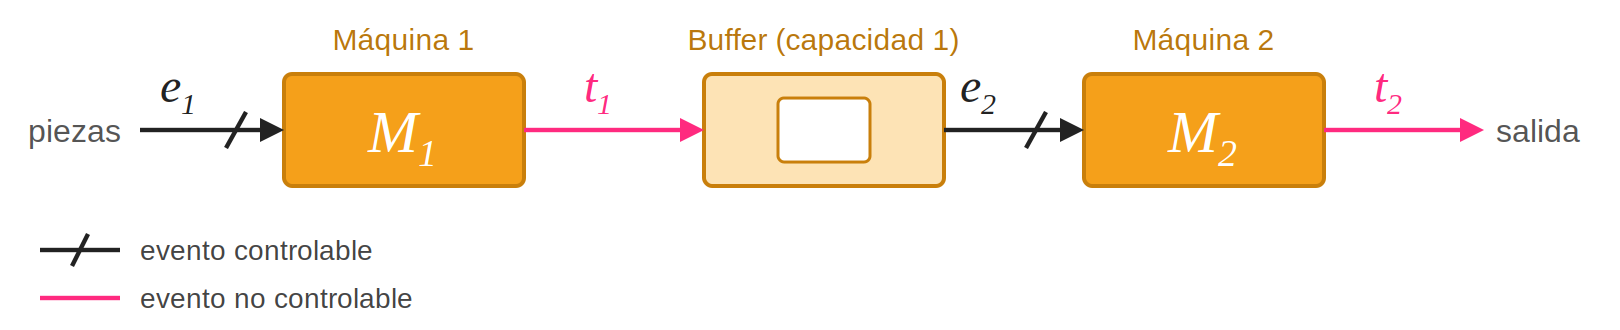

En la figura los eventos controlables ($e_1$, $e_2$) llevan una rayita sobre el arco y los no
controlables ($t_1$, $t_2$) van en color rosado, como en los dibujos de DESlab.

La máquina $M_1$ toma una pieza, la procesa y la deja en el buffer; la máquina $M_2$ toma la pieza
del buffer y la procesa. Se busca un supervisor que evite que el buffer se desborde ($M_1$ deja una
pieza con el buffer lleno) y que $M_2$ arranque con el buffer vacío, restringiendo lo menos posible
el funcionamiento de las máquinas y sin bloquear el sistema.

Pasos:

1. Modelar la planta $G = M_1 \parallel M_2$ e indicar qué eventos son controlables.
2. Modelar la especificación $B$ (el buffer) y construir $H = G \parallel B$, que marca el lenguaje deseado $K = L_m(H)$.
3. Verificar si $K$ es controlable.
4. Calcular el supremo sublenguaje controlable $K^{\uparrow C}$ con `supcontrollable`: el autómata
   que lo marca es el supervisor $S$, el menos restrictivo y no bloqueante.

In [1]:
#@title Instalación de DESlab desde GitHub (ejecute esta celda primero)
import importlib, json, shutil, subprocess, sys
from importlib.metadata import distribution

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q networkx graphviz
# se reinstala siempre la última versión de DESlab que está en GitHub
%pip install -q --force-reinstall --no-deps --no-cache-dir git+https://github.com/nebisman/deslab-py3.git

# si la celda se ejecuta de nuevo, DESlab se descarga de la memoria para
# que la siguiente celda importe la versión recién instalada
importlib.invalidate_caches()
for name in [m for m in sys.modules if m == "deslab" or m.startswith("deslab.")]:
    del sys.modules[name]

info = json.loads(distribution("deslab").read_text("direct_url.json") or "{}")
print("DESlab instalado desde el commit", info.get("vcs_info", {}).get("commit_id", "?")[:7])

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.
DESlab instalado desde el commit a8d254f


In [2]:
from deslab import *

## 1. Planta: pequeña fábrica sin fallas

Cada máquina $M_i$ tiene dos estados, $D$ (desocupada, inicial y marcado) y $O$ (ocupada), y dos
eventos:

| Evento | Significado | Tipo |
|---|---|---|
| $e_i$ | la máquina toma una pieza y empieza a trabajar | controlable |
| $t_i$ | la máquina termina y entrega la pieza | no controlable |


**Eventos controlables en DESlab.** Se indican con el parámetro `Sigcon`. Si se omite, DESlab
considera *todos* los eventos controlables, y la composición paralela une los conjuntos `Sigcon`
de los componentes; por eso hay que darlo en cada máquina.

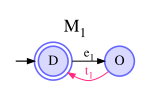

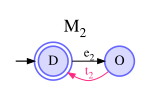

In [3]:
syms('D O B0 B1 e1 t1 e2 t2')
table1 = [(e1, 'e_1'), (t1, 't_1'), (e2, 'e_2'), (t2, 't_2')]

X1 = [D, O]
E1 = [e1, t1]
table1 = [(e1, 'e_1'), (t1, 't_1')]
table2 = [(e2, 'e_2'), (t2, 't_2')]



X2 = [D, O]
E2 = [e2, t2]   
T1 = [(D, e1, O), (O, t1, D)]
T2 = [(D, e2, O), (O, t2, D)]
M1 = fsa(X1, E1, T1, [D], [D], table1, Sigcon=[e1], name='$M_1$')
M2 = fsa(X2, E2, T2, [D], [D], table2, Sigcon=[e2], name='$M_2$')
draw(M1, M2)

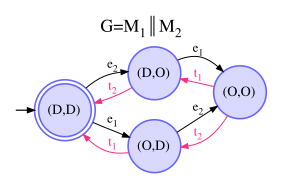

In [4]:
G = (M1 // M2).setpar(name='$G = M_1 \\parallel M_2$')
draw(G)


## 2. Especificación: buffer de capacidad 1

El buffer  $B$ tiene dos estados: $B0$ (vacío) y $B1$ (lleno). $t_1$ indica que $M_1$ deja una pieza y  $e_2$ indica que $M_2$ la retira.
Como $B$ no tiene $t_1$ en el estado $B1$ ni $e_2$ en el estado $B0$, prohíbe el desborde y que
$M_2$ arranque sin pieza. En $B$ solo $e_2$ es controlable (`Sigcon=[e2]`): si se omite,
DESlab considera controlables todos los eventos de $B$, y $H$ y el supervisor heredarían
$t_1$ como controlable.

$H = G \parallel B$ combina la planta con la especificación y marca el lenguaje deseado $K = L_m(H)$.


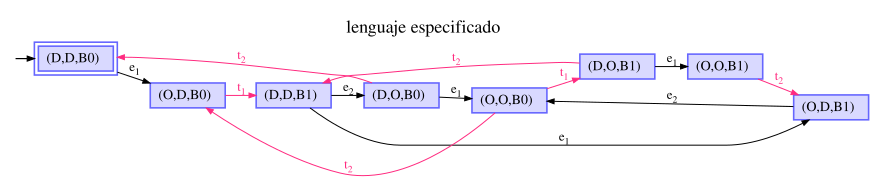

In [5]:
XB = [B0, B1]
EB = [t1, e2]
TB = [(B0, t1, B1), (B1, e2, B0)]
tableB = [(t1, 't_1'), (e2, 'e_2')]
B = fsa(XB, EB, TB, [B0], [B0], table=tableB, Sigcon=[e2], name='$B$ -- bufer', type='specification')

H = (G // B).setpar(name='lenguaje especificado', style='verifier')
draw(H)



## 3. ¿Es controlable $K$?

$K$ es controlable con respecto a $L(G)$ y a los eventos no controlables $\Sigma_{uc}$ si
$\overline{K}\,\Sigma_{uc} \cap L(G) \subseteq \overline{K}$: la especificación nunca debe prohibir un
evento no controlable que la planta puede ejecutar, porque el supervisor no lo puede impedir.
`iscontrollable(H, G)` hace esa prueba. La celda lista además los estados de $H$ donde falla.

In [6]:
print('¿K es controlable?', iscontrollable(H, G))

Sigma_uc = G.Sigma - G.Sigcon
for xh in sorted(H.X):
    m1 , m2 , b  = xh
    prohibidos = (G.Gamma((m1,m2)) & Sigma_uc) - H.Gamma(xh)
    if prohibidos:
        print(f'en el estado {xh} H prohíbe {sorted(prohibidos)}, que no es controlable')



¿K es controlable? False
en el estado ('O', 'D', 'B1') H prohíbe ['t1'], que no es controlable
en el estado ('O', 'O', 'B1') H prohíbe ['t1'], que no es controlable


En los dos estados la máquina 1 trabaja con el buffer lleno: cuando termine ($t_1$, no
controlable) el buffer se desborda, y el supervisor no lo puede evitar. Hay que actuar antes,
deshabilitando $e_1$ cuando el buffer está lleno. Eso es lo que calcula el sublenguaje
controlable supremo.

## 4. Supervisor: sublenguaje controlable supremo

Vamos a correr por pasos el algoritmo de cálculo del lenguaje controlable supremo

removemos el siguiente estado que viola controlabilidad
('O', 'D', 'B1')
removemos el siguiente estado que viola controlabilidad
('O', 'O', 'B1')


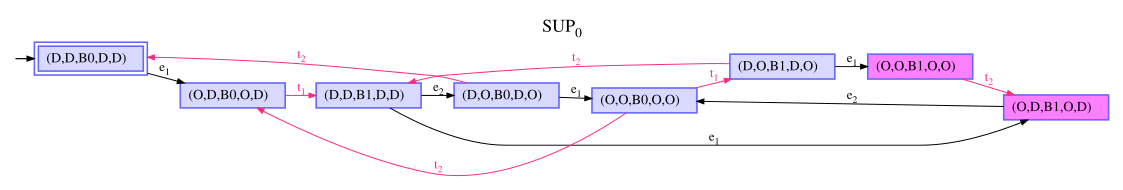

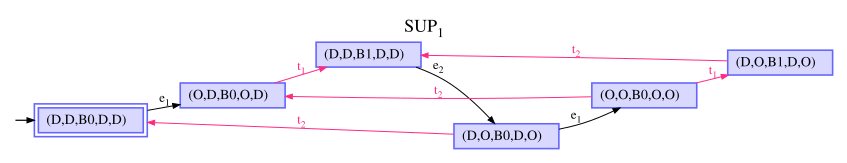

In [7]:
# Creamos el automata inicial

S0 = H // G.setpar(Xm=G.X)
S0 = S0.setpar(style='rectangle',name='$SUP_0$')
S1 = S0

# buscamos las violaciones de controlabilidad
for xh in sorted(S0.X):
     y, x = xh[:3], xh[3:]   # estado de H (M1, M2, B) y estado de G (M1, M2)
     G_events_uc = G.Gamma(x) & Sigma_uc
     if not (G_events_uc <= S0.Gamma(xh)):
         print("removemos el siguiente estado que viola controlabilidad")
         print(y)
         S0 = S0.highlightstates(xh)
         S1 = S1.deletestate(xh).setpar(style='rectangle') 
         

S1 = trim(S1).setpar(style='rectangle',name='$SUP_1$')
draw(S0, S1)

no hay violaciones de controlabilidad en ('D', 'D', 'B0', 'D', 'D')
no hay violaciones de controlabilidad en ('D', 'D', 'B1', 'D', 'D')
no hay violaciones de controlabilidad en ('D', 'O', 'B0', 'D', 'O')
no hay violaciones de controlabilidad en ('D', 'O', 'B1', 'D', 'O')
no hay violaciones de controlabilidad en ('O', 'D', 'B0', 'O', 'D')
no hay violaciones de controlabilidad en ('O', 'O', 'B0', 'O', 'O')
no hay más violaciones: el supervisor final es SUP_1


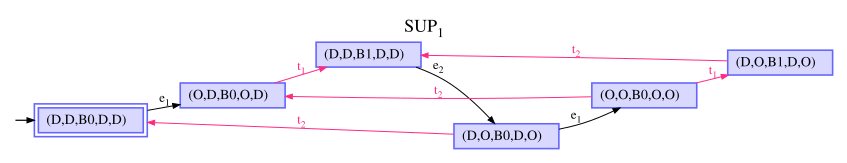

In [8]:
# segunda iteración: buscamos violaciones de controlabilidad en SUP_1
S2 = S1.setpar(name='$SUP_2$')
removidos = []
for xh in sorted(S1.X):
    y, x = xh[:3], xh[3:]   # estado de H y estado de G
    G_events_uc = G.Gamma(x) & Sigma_uc
    if not (G_events_uc <= S1.Gamma(xh)):
        print("removemos el siguiente estado que viola controlabilidad")
        print(y)
        removidos.append(xh)
        S1 = S1.highlightstates(xh)
        S2 = S2.deletestate(xh)
    else:
        print(f'no hay violaciones de controlabilidad en {xh}')

if removidos:
    S2 = trim(S2).setpar(style='rectangle', name='$SUP_2$')
    draw(S1, S2)
else:
    print("no hay más violaciones: el supervisor final es SUP_1")
    draw(S1)


## 5. ¿Es un supervisor controlable y no bloqueante?

In [9]:
print('¿S es controlable?         ', iscontrollable(S1, G))
print('¿Lm(S) ⊆ K?                ', S1 <= H)
print('¿S es no bloqueante (trim)?', S1 == trim(S1))

¿S es controlable?          True
¿Lm(S) ⊆ K?                 True
¿S es no bloqueante (trim)? True


## 6. Todo con una única función de DESlab

`supcontrollable(H, G)` devuelve un autómata que marca $K^{\uparrow C}$, el mayor sublenguaje
controlable de $K$.

`supcontrollable` numera los estados si se usa con `renamestates=True`


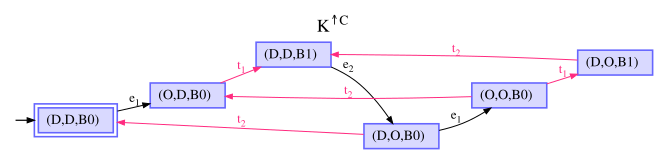

In [10]:
SUP = supcontrollable(H, G).setpar(style='verifier')

#S = supcontrollable(H, G, verbose=True, renamestates=True) #si quieres que los estados de S se renombren con números consecutivos
draw(SUP)